In [41]:
# Import libraries for data processing, visualization, and classification.
import warnings, os, json, joblib
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    matthews_corrcoef, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, MultinomialNB


In [42]:
# Set reproducible options and prepare folders for project files.
RANDOM_STATE = 42               
NB_VARIANT = "gaussian"        

os.makedirs("model", exist_ok=True)
print('Environment ready.')

Environment ready.


In [43]:
# UCI official ZIP -> read bank/bank-full.csv
import io, zipfile, requests


OUTER_ZIP_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # outer zip that contains bank.zip and bank-additional.zip
TARGET_INNER_ZIP = "bank-additional.zip"          
TARGET_CSV_SUFFIX = "bank-additional-full.csv"  
LOAD_SEP  = ";"                   
TARGET    = "y"                
DROP_COLUMNS = ["duration"]    

# 1) Download the outer ZIP
resp = requests.get(OUTER_ZIP_URL, timeout=60)
resp.raise_for_status()

with zipfile.ZipFile(io.BytesIO(resp.content)) as outer_zf:
    # 2) Find bank.zip inside the outer archive
    members = outer_zf.namelist()
    inner_zip_member = None
    for m in members:
        if m.lower().endswith("/" + TARGET_INNER_ZIP) or m.lower() == TARGET_INNER_ZIP:
            inner_zip_member = m
            break

    if inner_zip_member is None:
        raise FileNotFoundError(f"Could not find {TARGET_INNER_ZIP!r} inside {OUTER_ZIP_URL}. Members:\n" + "\n".join(members))

    # 3) Read bank.zip into memory
    with outer_zf.open(inner_zip_member) as inner_zip_file:
        inner_zip_bytes = inner_zip_file.read()

# 4) Open bank.zip (inner) and locate bank-full.csv by suffix
with zipfile.ZipFile(io.BytesIO(inner_zip_bytes)) as inner_zf:
    inner_members = inner_zf.namelist()
    csv_member = None
    for m in inner_members:
        if m.lower().endswith("/" + TARGET_CSV_SUFFIX) or m.lower() == TARGET_CSV_SUFFIX:
            csv_member = m
            break

    if csv_member is None:
        raise FileNotFoundError(f"Could not find {TARGET_CSV_SUFFIX!r} in {TARGET_INNER_ZIP}. Members:\n" + "\n".join(inner_members))

    # 5) Read CSV (UCI uses semicolon separator)
    with inner_zf.open(csv_member) as f:
        df = pd.read_csv(f, sep=LOAD_SEP)

print(df.shape)
df.head()


(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [44]:
# Inspect the dataset structure, types, and target distribution.

print('Shape:', df.shape)
print('Columns:', list(df.columns))
display(df.head())
print('Dtypes:')
print(df.dtypes)
print('Missing values per column:')
print(df.isna().sum())
print('Target distribution (raw):')
print(df[TARGET].value_counts())

Shape: (41188, 21)
Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Dtypes:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object
Missing values per column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y    

In [45]:
# Convert the subscription target labels into numeric classes.

# Map common yes/no -> 1/0
if df[TARGET].dtype == 'O':
    df[TARGET] = df[TARGET].str.strip().str.lower().map({'yes':1, 'no':0})


if df[TARGET].isna().any():
    bad = df.loc[df[TARGET].isna(), TARGET]
    raise ValueError(f"Unexpected target labels found; cannot map to 0/1. Offending values: {bad.unique()[:5]}")

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0


In [46]:
# Remove optional columns that could cause target leakage.

# Drop optional columns (e.g., leakage)
for c in DROP_COLUMNS:
    if c in df.columns:
        df = df.drop(columns=[c])
print('Dropped columns:', DROP_COLUMNS)
print('Columns after dropping:', list(df.columns))

Dropped columns: ['duration']
Columns after dropping: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [47]:
# Remove records that do not have a target label.
# Remove rows with missing target
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
print('Shape after dropping missing target:', df.shape)

Shape after dropping missing target: (41188, 20)


Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric columns: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


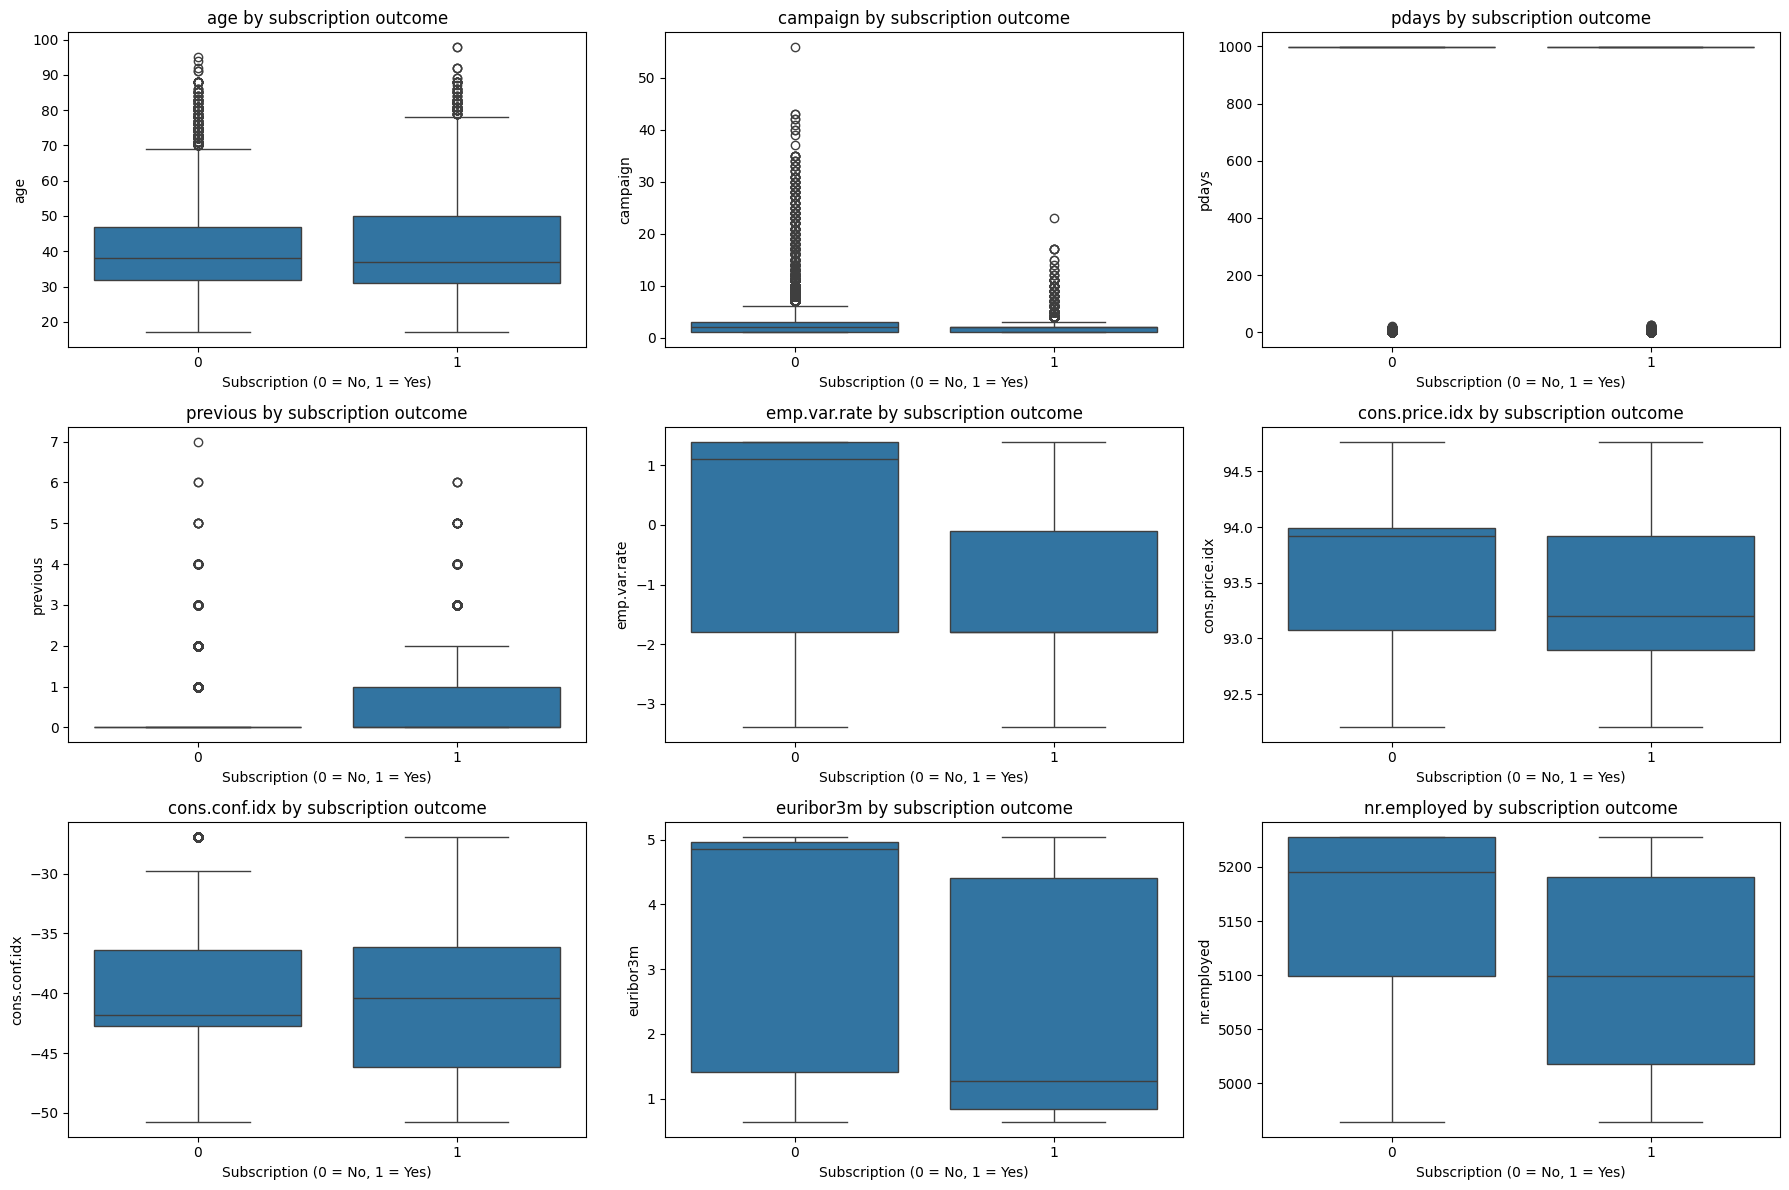

In [48]:
# Identify feature types and compare numeric values by class.
# Identify column types
cat_cols = [c for c in df.columns if df[c].dtype == 'O' and c != TARGET]
num_cols = [c for c in df.columns if (np.issubdtype(df[c].dtype, np.number)) and c != TARGET]
print('Categorical columns:', cat_cols)
print('Numeric columns:', num_cols)

# Compare numeric feature distributions by target class.
ncols = 3
nrows = math.ceil(len(num_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows), squeeze=False)

for ax, column in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x=TARGET, y=column, order=[0, 1], ax=ax)
    ax.set_title(f'{column} by subscription outcome')
    ax.set_xlabel('Subscription (0 = No, 1 = Yes)')
    ax.set_ylabel(column)

for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [49]:
# Split the prepared data into training and test sets.
RANDOM_STATE = 42
# Split 80/20 (Train/Test)

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print('Train class distribution:', np.bincount(y_train))
print('Test class distribution:', np.bincount(y_test))

Train: (32950, 19) Test: (8238, 19)
Train class distribution: [29238  3712]
Test class distribution: [7310  928]


In [50]:
# Save a balanced sample of test rows for the Streamlit app.
# Create a small TEST CSV from your existing split (includes target `y`)
test_sample = pd.concat([X_test, y_test.rename("y")], axis=1).copy()

test_sample = (
    test_sample
    .groupby('y', group_keys=False)
    .apply(lambda g: g.sample(min(len(g), 100), random_state=42))  # 100 from each class → ~200
    .reset_index(drop=True)
)

# Save with the same separator as source (UCI bank-full.csv uses ';')
test_sample.to_csv("test_data.csv", sep=";", index=False)
print("Saved → test_data.csv")

Saved → test_data.csv


In [51]:
# Build preprocessing pipelines for numeric and categorical features.

# Preprocessors

num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

# For LR & KNN (scale numerics)
preprocess_scaled = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", num_imputer), ("scaler", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputer", cat_imputer),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ],
    remainder="drop",
    sparse_threshold=0
)

# For tree-based & NB (no scaling)
preprocess_basic = ColumnTransformer(
    transformers=[
        ("num", num_imputer, num_cols),
        ("cat", Pipeline([("imputer", cat_imputer),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ],
    remainder="drop",
    sparse_threshold=0
)


def get_feature_names_from_fitted_preprocessor(fitted_preproc):
    if hasattr(fitted_preproc, "get_feature_names_out"):
        return list(fitted_preproc.get_feature_names_out())
    names = []
    for name, trans, cols in fitted_preproc.transformers_:
        if name == "remainder":
            continue
        if hasattr(trans, "named_steps") and "ohe" in trans.named_steps:
            ohe = trans.named_steps["ohe"]
            names.extend(list(ohe.get_feature_names_out(cols)))
        elif hasattr(trans, "get_feature_names_out"):
            names.extend(list(trans.get_feature_names_out(cols)))
        else:
            names.extend(list(cols))
    return names

print('Preprocessors ready.')


Preprocessors ready.


In [52]:
# Configure the five requested classification models.
NB_VARIANT = "gaussian"
# Models
models = {}

# 1) Logistic Regression
models["logreg"] = Pipeline(steps=[
    ("prep", preprocess_scaled),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

# 2) Decision Tree
models["tree"] = Pipeline(steps=[
    ("prep", preprocess_basic),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
])

# 3) KNN
models["knn"] = Pipeline(steps=[
    ("prep", preprocess_scaled),    
    ("clf", KNeighborsClassifier(n_neighbors=5))
])

# 4) Naive Bayes
if NB_VARIANT.lower().startswith("multi"):
    nb_est = MultinomialNB()   # requires non-negative features (e.g., counts)
else:
    nb_est = GaussianNB()
models["nb"] = Pipeline(steps=[
    ("prep", preprocess_basic),
    ("clf", nb_est)
])

# 5) Support Vector Machine
models["svm"] = Pipeline(steps=[
    ("prep", preprocess_scaled),
    ("clf", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

In [53]:
# Train each classifier and calculate test-set metrics.

# ===============================
# Train & Evaluate
# ===============================

def auc_safely(y_true, proba):
    if proba is None:
        return np.nan
    try:
        # If model outputs shape (n_samples, 2), use prob for class 1
        if isinstance(proba, np.ndarray) and proba.ndim == 2 and proba.shape[1] >= 2:
            return roc_auc_score(y_true, proba[:, 1])
        else:
            return roc_auc_score(y_true, proba)
    except Exception:
        return np.nan


results = []
trained = {}

for name, pipe in models.items():
    print(f"Training: {name}")
    pipe.fit(X_train, y_train)
    trained[name] = pipe

    # Predict on test
    y_pred = pipe.predict(X_test)

    # Probabilities (if available)
    y_proba = None
    if hasattr(pipe, "predict_proba"):
        try:
            y_proba = pipe.predict_proba(X_test)
        except Exception:
            y_proba = None  # fall back gracefully if a model raises

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
    rec  = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1   = f1_score(y_test, y_pred, average="macro", zero_division=0)
    mcc  = matthews_corrcoef(y_test, y_pred)
    auc  = auc_safely(y_test, y_proba)

    results.append({
        "model": name, "Accuracy": acc, "AUC": auc,
        "Precision": prec, "Recall": rec, "F1": f1, "MCC": mcc
    })

metrics_df = pd.DataFrame(results).set_index("model").sort_values("AUC", ascending=False)
display(metrics_df.style.format("{:.4f}"))

# Save metrics
metrics_path = "model/metrics_summary.csv"
metrics_df.to_csv(metrics_path, index=True)
print("Saved:", metrics_path)


Training: logreg
Training: tree
Training: knn
Training: nb
Training: svm


,Accuracy,AUC,Precision,Recall,F1,MCC
model,,,,,,
logreg,0.8350,0.8009,0.6591,0.7528,0.6856,0.4011
svm,0.8577,0.7828,0.6820,0.7594,0.7087,0.4346
nb,0.8565,0.7756,0.6592,0.6882,0.6716,0.3462
knn,0.8972,0.7433,0.7502,0.6387,0.6722,0.3725
tree,0.8472,0.6199,0.6186,0.6194,0.6190,0.2381


Saved: model/metrics_summary.csv


In [54]:
# Save trained pipelines and their processed feature names.

# Save artifacts & feature columns
for name, pipe in trained.items():
    out_path = f"model/model_{name}.joblib"
    # Use compression: xz yields smaller files; zlib (int) is faster
    if name == "knn":  # typically the larger model
        joblib.dump(pipe, out_path, compress=("xz", 3))
    else:
        joblib.dump(pipe, out_path, compress=3)
    print("Saved:", out_path)


# save feature columns from any trained pipeline (use the first)

first_model = next(iter(trained.values()))
fitted_preproc = first_model.named_steps["prep"]

feat_names = get_feature_names_from_fitted_preprocessor(fitted_preproc)
with open("model/feature_columns.json", "w") as f:
    json.dump({"features": feat_names}, f, indent=2)
print("Saved: model/feature_columns.json (feature names after preprocessing)")

print("\nArtifacts in ./model:")
print(os.listdir("model"))




Saved: model/model_logreg.joblib
Saved: model/model_tree.joblib
Saved: model/model_knn.joblib
Saved: model/model_nb.joblib
Saved: model/model_svm.joblib
Saved: model/feature_columns.json (feature names after preprocessing)

Artifacts in ./model:
['feature_columns.json', 'metrics_summary.csv', 'model_knn.joblib', 'model_logreg.joblib', 'model_nb.joblib', 'model_svm.joblib', 'model_tree.joblib']


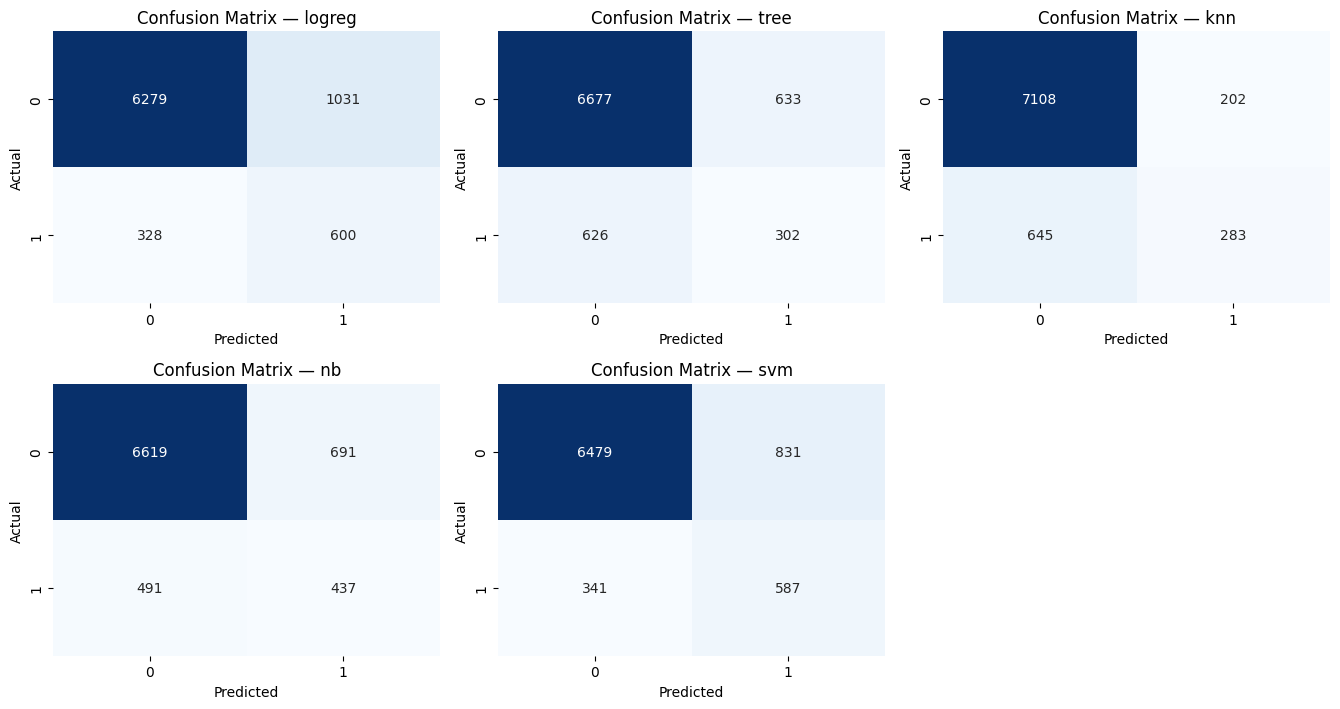

In [55]:
# Compare model predictions with a grid of confusion matrices.
# Visualization: Confusion Matrices

def plot_confusion_matrices_grid(trained, X_test, y_test, max_cols=3, cmap="Blues"):
    names = list(trained.keys())
    m = len(names)
    cols = min(max_cols, m)
    rows = math.ceil(m / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4.5*cols, 3.6*rows))
    axes = np.array(axes).reshape(rows, cols)

    for i, name in enumerate(names):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        pipe = trained[name]
        y_pred = pipe.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False, ax=ax)
        ax.set_title(f"Confusion Matrix — {name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    # Hide any unused axes
    for j in range(m, rows*cols):
        r, c = divmod(j, cols)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()

# Call it
plot_confusion_matrices_grid(trained, X_test, y_test, max_cols=3)


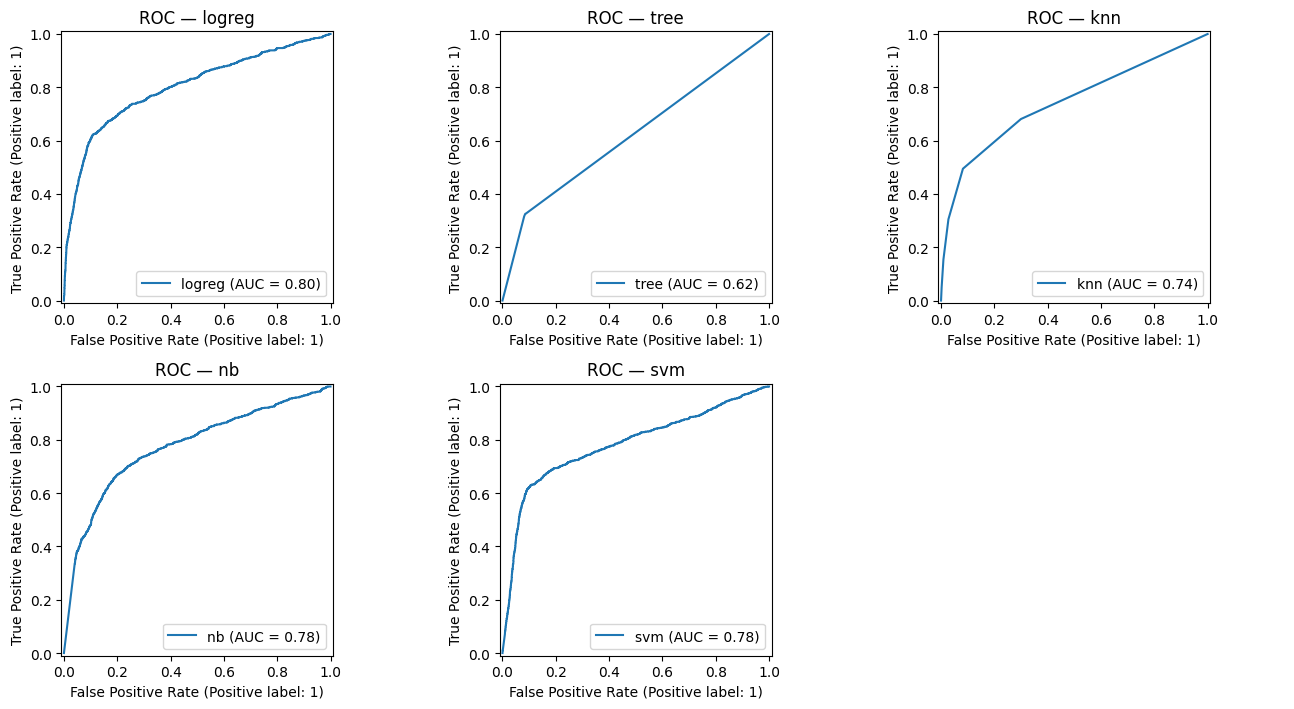

In [56]:
# Compare model discrimination using ROC curves.
# Visualization: ROC Curves

def plot_roc_curves_grid(trained, X_test, y_test, max_cols=3):
    # Keep only models that expose predict_proba
    names = [n for n, p in trained.items() if hasattr(p, "predict_proba")]
    if not names:
        print("No models support predict_proba — skipping ROC grid.")
        return

    m = len(names)
    cols = min(max_cols, m)
    rows = math.ceil(m / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 3.6 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for i, name in enumerate(names):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        pipe = trained[name]

        try:
            proba = pipe.predict_proba(X_test)
        except Exception as e:
            ax.axis("off")
            ax.set_title(f"ROC — {name}\n(predict_proba failed)")
            continue

        # Accept either 2D proba (use positive class column) or 1D scores
        if isinstance(proba, np.ndarray) and proba.ndim == 2 and proba.shape[1] >= 2:
            scores = proba[:, 1]
        else:
            scores = proba

        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=ax)
        ax.set_title(f"ROC — {name}")

    # Hide any unused axes
    for j in range(m, rows * cols):
        r, c = divmod(j, cols)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()


# Call it
plot_roc_curves_grid(trained, X_test, y_test, max_cols=3)


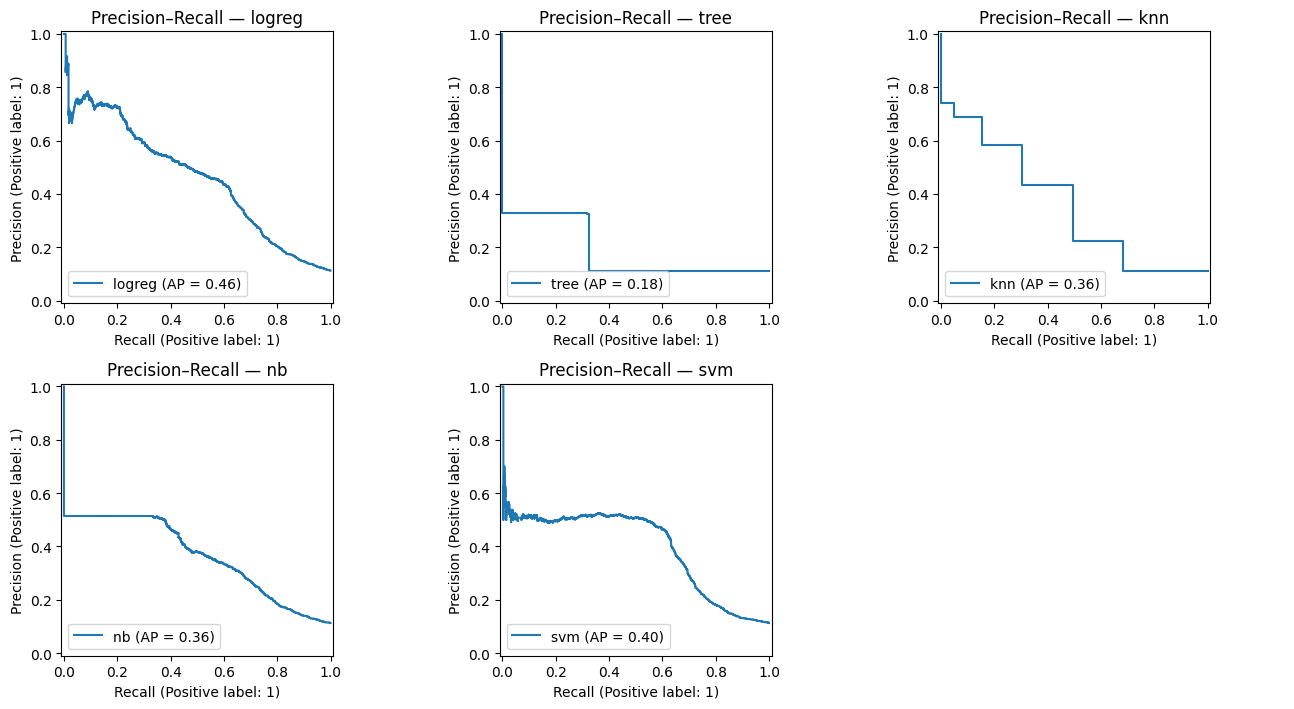

In [57]:
# Compare positive-class retrieval using precision-recall curves.
# Visualization: Precision-Recall Curves


def plot_pr_curves_grid(trained, X_test, y_test, max_cols=3):
    # Filter to models that expose predict_proba
    names = [n for n, p in trained.items() if hasattr(p, "predict_proba")]
    if not names:
        print("No models support predict_proba — skipping PR grid.")
        return

    m = len(names)
    cols = min(max_cols, m)
    rows = math.ceil(m / cols)

    # Slightly compact default size; adjust if you want smaller/larger plots
    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 3.6 * rows))
    axes = np.array(axes).reshape(rows, cols)

    for i, name in enumerate(names):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        pipe = trained[name]

        # Try to obtain probabilities
        try:
            proba = pipe.predict_proba(X_test)
        except Exception:
            ax.axis("off")
            ax.set_title(f"Precision–Recall — {name}\n(predict_proba failed)")
            continue

        # Positive-class scores: use column index 1 if 2D, else use the 1D scores
        if isinstance(proba, np.ndarray) and proba.ndim == 2 and proba.shape[1] >= 2:
            scores = proba[:, 1]
        else:
            scores = proba

        PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
        ax.set_title(f"Precision–Recall — {name}")

    # Hide unused axes
    for j in range(m, rows * cols):
        r, c = divmod(j, cols)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()


# Call it
plot_pr_curves_grid(trained, X_test, y_test, max_cols=3)


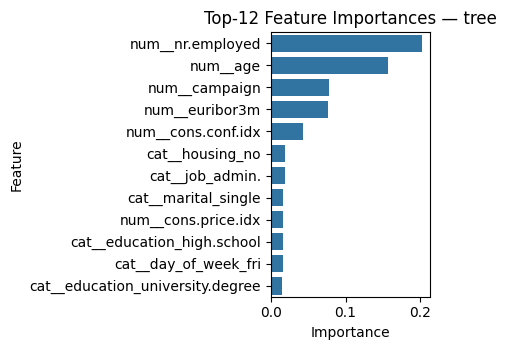

In [58]:
# Show feature importance for models that provide it.
# Visualization: Feature Importances for tree-based models

def plot_feature_importances_grid(trained, X_ref, top_k=12, max_cols=3):
    eligible = []
    for name, pipe in trained.items():
        clf = pipe.named_steps.get("clf", None)
        if clf is not None and hasattr(clf, "feature_importances_"):
            eligible.append(name)

    if not eligible:
        print("No tree-based models with feature_importances_ — skipping.")
        return

    m = len(eligible)
    cols = min(max_cols, m)
    rows = math.ceil(m / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4.5*cols, 3.6*rows))
    axes = np.array(axes).reshape(rows, cols)

    for i, name in enumerate(eligible):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        pipe = trained[name]
        clf = pipe.named_steps["clf"]
        importances = clf.feature_importances_

        # get expanded feature names after preprocessing
        feat_names = get_feature_names_from_fitted_preprocessor(fitted_preproc)
        idx = np.argsort(importances)[::-1][:top_k]
        vals = importances[idx]
        labels = [feat_names[j] if j < len(feat_names) else f"f{j}" for j in idx]

        sns.barplot(x=vals, y=labels, orient="h", ax=ax)
        ax.set_title(f"Top-{top_k} Feature Importances — {name}")
        ax.set_xlabel("Importance")
        ax.set_ylabel("Feature")

    # Hide any unused axes
    for j in range(m, rows*cols):
        r, c = divmod(j, cols)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()

# Call it (use train+val or full train features to derive names)
plot_feature_importances_grid(trained, X_train, top_k=12, max_cols=3)


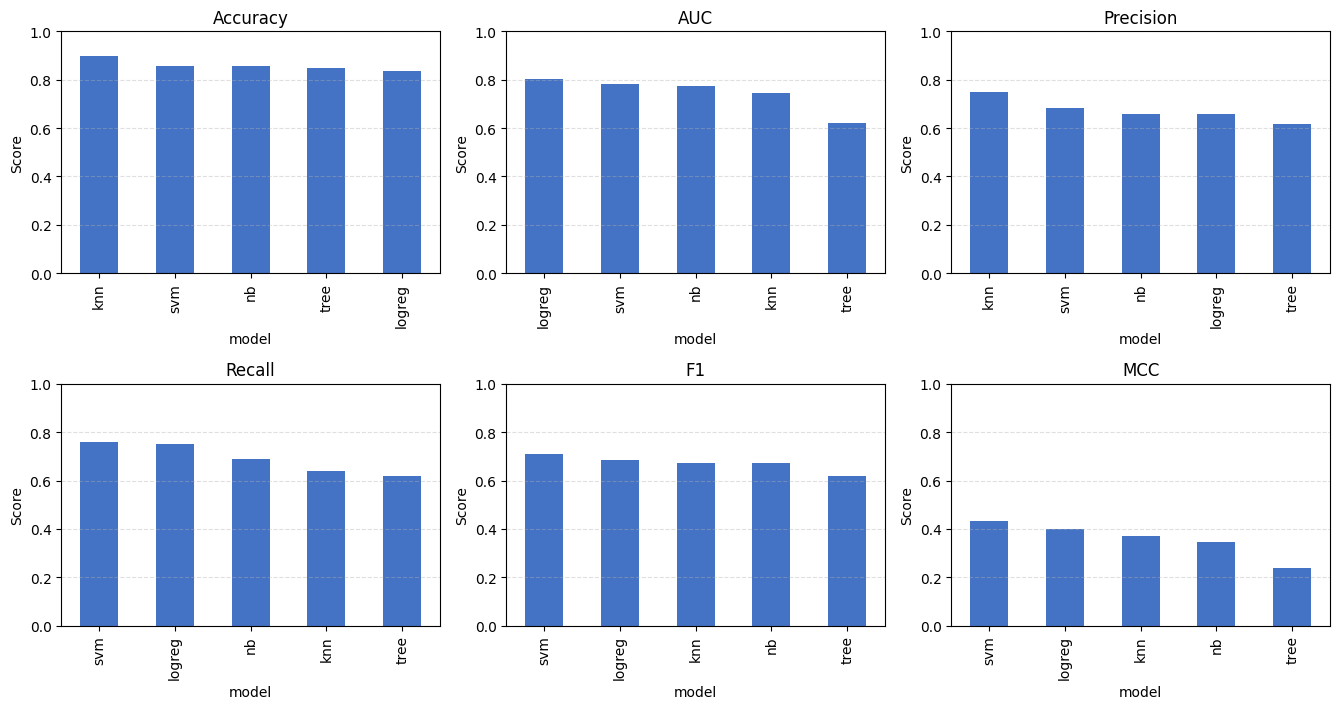

In [59]:
# Plot the evaluation metrics for side-by-side comparison.
# Visualization: Metrics Bar Charts
def compare_metrics_grid(metrics_df, metrics=("Accuracy", "AUC", "Precision", "Recall", "F1", "MCC")):
    k = len(metrics)
    cols = min(3, k)                 # 3 panels per row
    rows = math.ceil(k / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4.5*cols, 3.6*rows))
    axes = np.array(axes).reshape(rows, cols)

    for i, met in enumerate(metrics):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        (metrics_df[met]
         .sort_values(ascending=False)
         .plot(kind="bar", ax=ax, color="#4472C4"))
        ax.set_title(met)
        ax.set_ylabel("Score")
        ax.set_ylim(0, 1)  # if all are in [0,1]
        ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Hide any unused axes
    for j in range(k, rows*cols):
        r, c = divmod(j, cols)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()

# Call it
compare_metrics_grid(metrics_df)


In [60]:
# Format the model comparison metrics as a Markdown table.
def to_markdown_table(df):
    header = "| ML Model | Accuracy | AUC | Precision | Recall | F1 | MCC |"
    sep    = "|---|---:|---:|---:|---:|---:|---:|"
    lines = [header, sep]
    for r in df.itertuples():
        line = f"| {r.Index} | {r.Accuracy:.4f} | {r.AUC:.4f} | {r.Precision:.4f} | {r.Recall:.4f} | {r.F1:.4f} | {r.MCC:.4f} |"
        lines.append(line)
    return "\n".join(lines)

md = to_markdown_table(metrics_df)
print(md)

| ML Model | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| logreg | 0.8350 | 0.8009 | 0.6591 | 0.7528 | 0.6856 | 0.4011 |
| svm | 0.8577 | 0.7828 | 0.6820 | 0.7594 | 0.7087 | 0.4346 |
| nb | 0.8565 | 0.7756 | 0.6592 | 0.6882 | 0.6716 | 0.3462 |
| knn | 0.8972 | 0.7433 | 0.7502 | 0.6387 | 0.6722 | 0.3725 |
| tree | 0.8472 | 0.6199 | 0.6186 | 0.6194 | 0.6190 | 0.2381 |
